# 02 — Comparison with the 2018–2020 measles data (São Paulo State)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sir_sim import (load_grid, get, threshold_cases, final_size_fraction, ps_table,
                     ps_at, p_small_theory, R0)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

## Loading simulation data

In [2]:
grid = load_grid('results')
N_sim = sorted({k[0] for k in grid})
eps_sim = sorted({k[1] for k in grid})
eps_pos = [e for e in eps_sim if e > 0]        
print('simulated N:', N_sim)

simulated N: [1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000]


## Loading real epidemic data

In [3]:
df = pd.read_csv('data/municipalities_SP.csv')
df = df.groupby(['ID_MN_RESI'])['CASO'].sum()
df = df.reset_index(name='CASOS')
df = df[df.CASOS >= 1].copy()
df['ID_MN_RESI'] = df['ID_MN_RESI'].astype(int)

In [4]:
pop = pd.read_csv('data/age_groups_municipalities.csv')
pop['Municipio'] = pop['Municipio'].astype(str).str[:6]
pop = pop[pop['Municipio'].str.startswith('35')]
pop = (pop[['Municipio', 'Total']]
       .rename(columns={'Municipio': 'mun_code', 'Total': 'pop'})
       .reset_index(drop=True))
pop['mun_code'] = pop['mun_code'].astype(int)

In [5]:
df_pop = pd.merge(df, pop, how='left', left_on='ID_MN_RESI', right_on='mun_code')
df_pop = df_pop.drop(columns=['mun_code'])

In [6]:
print('without population:', df_pop['pop'].isna().sum())
df_pop = df_pop.dropna(subset=['pop']).copy()

without population: 0


In [7]:
df_pop['C_inf'] = df_pop['CASOS'] / df_pop['pop']
print(len(df_pop), 'municipalities with >= 1 case')

310 municipalities with >= 1 case


In [12]:
sum(df_pop['pop'] < 2000) # below 2000 (1000-2000 category)

1

In [14]:
sum(df_pop['pop'] < 5000) # below 5000 (5000-2000 category + 1000-2000 category)

16

## Dividing cities into population sizes (small, mid, large, etc)

In [8]:
MERGE_BELOW = 5_000
N_edges = [N for N in N_sim if N >= MERGE_BELOW]             # class boundaries
edges = [0] + N_edges + [np.inf]
labels = ([f'< {N_edges[0]:,}']
          + [f'{a:,}–{b:,}' for a, b in zip(N_edges[:-1], N_edges[1:])]
          + [f'> {N_edges[-1]:,}'])
df_pop['pop_class'] = pd.cut(df_pop['pop'], bins=edges, labels=labels, right=False)

In [9]:
lower = [N_sim[0]] + N_edges
upper = N_edges + [None]
bounds = dict(zip(labels, zip(lower, upper)))
classes = [c for c in labels if (df_pop.pop_class == c).any()]
 
df_pop.groupby('pop_class', observed=False).size().rename('n_municipalities')

pop_class
< 5,000            16
5,000–10,000       25
10,000–20,000      51
20,000–50,000      79
50,000–100,000     58
100,000–200,000    40
200,000–500,000    32
> 500,000           9
Name: n_municipalities, dtype: int64

## Getting the simulated sizes for N and eps

In [10]:
rows = []
for N in N_sim:
    for e in eps_pos:
        c, _ = get(grid, N, e)
        thr = threshold_cases(N, e)
        small = c < thr
        big = c[~small]
        rows.append(dict(N=N, eps=e, p_s=small.mean(), C_s=thr / N,
                         C_small=c[small].mean() / N if small.any() else np.nan,
                         C_big=big.mean() / N if big.size else np.nan,
                         C_big_lo=np.percentile(big, 2.5) / N if big.size else np.nan,
                         C_big_hi=np.percentile(big, 97.5) / N if big.size else np.nan))
sim = pd.DataFrame(rows)

## Figure 4: comparison of epidemic size with real data 

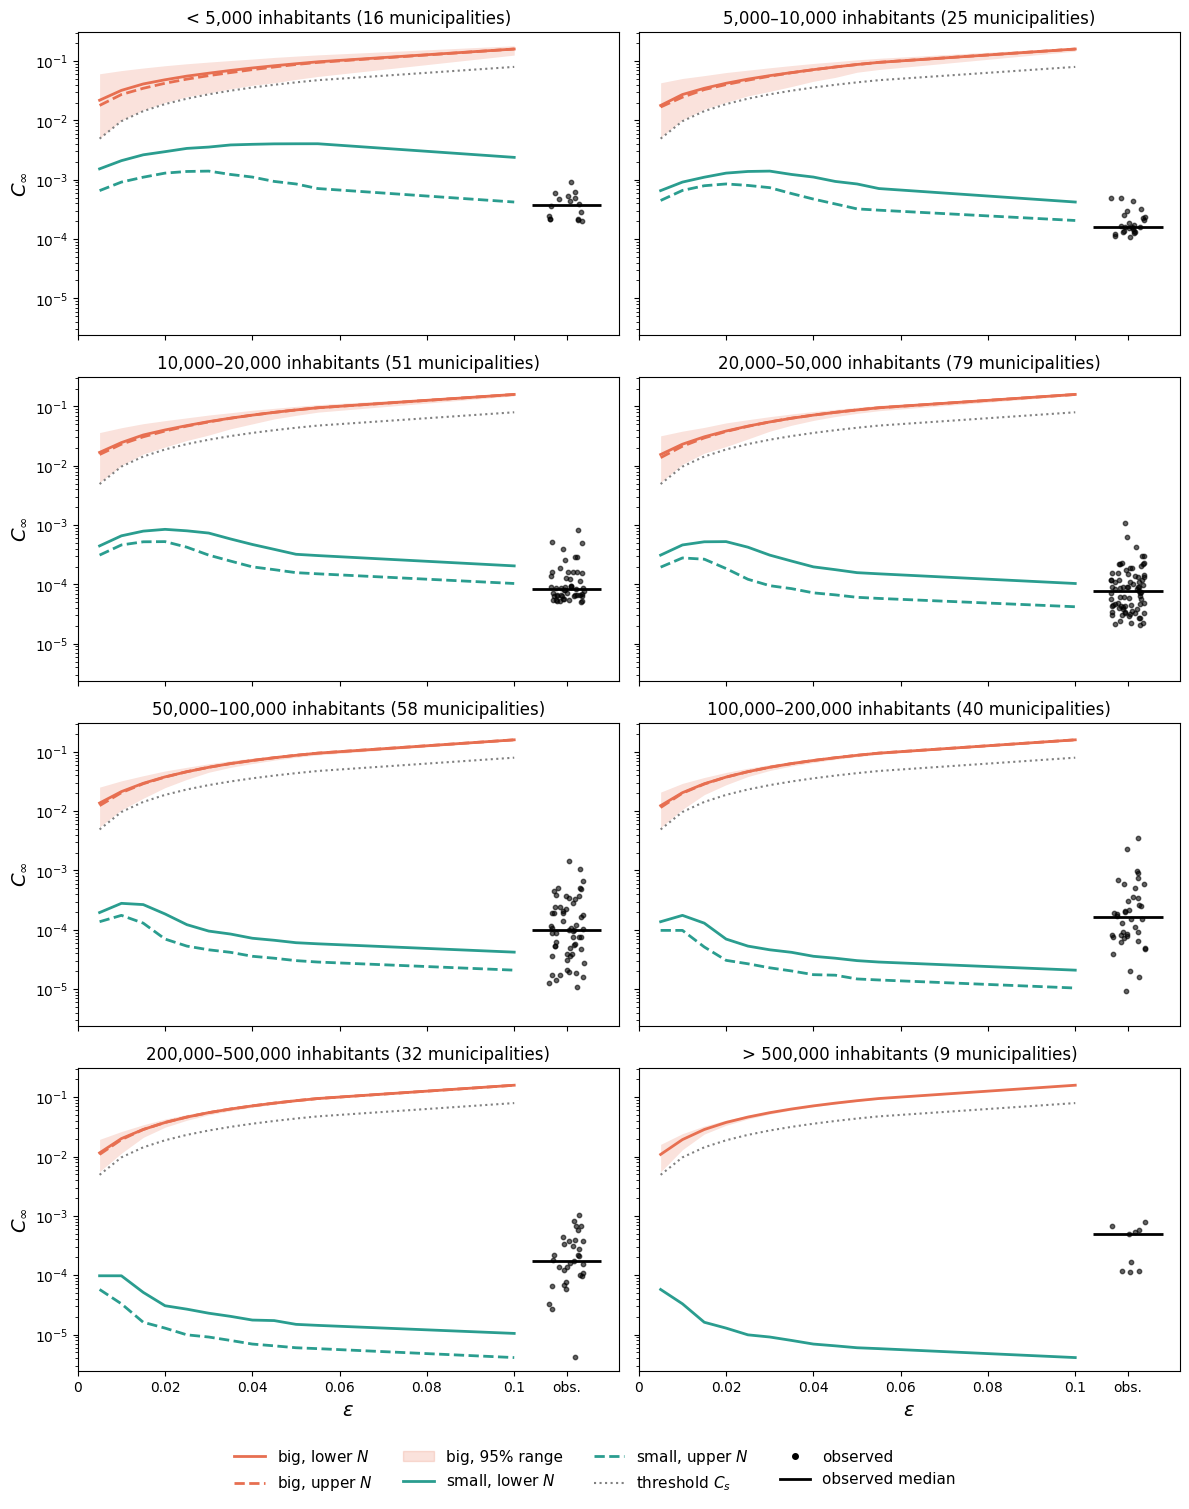

In [11]:
col_big, col_small = '#E76F51', '#2A9D8F'
x_obs = max(eps_pos) * 1.12                                   # where the observed points are drawn
rng = np.random.default_rng(0)                                # jitter, only for visibility
 
ncol = 2
nrow = int(np.ceil(len(classes) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(12, 3.6 * nrow), sharex=True, sharey=True, squeeze=False)
for ax, cl in zip(axs.flat, classes):
    N_lo, N_hi = bounds[cl]
    for N, ls in [(N_lo, '-'), (N_hi, '--')]:
        if N is None:
            continue
        s = sim[sim.N == N]
        if ls == '-':
            ax.fill_between(s.eps, s.C_big_lo, s.C_big_hi, color=col_big, alpha=0.2, lw=0)
        ax.plot(s.eps, s.C_big, ls, color=col_big, lw=2)
        ax.plot(s.eps, s.C_small, ls, color=col_small, lw=2)
    s = sim[sim.N == N_lo]
    ax.plot(s.eps, s.C_s, ':', color='grey', lw=1.5)          # small/big threshold, C_det/2
 
    obs = df_pop[df_pop.pop_class == cl].C_inf.to_numpy()
    ax.scatter(x_obs + rng.uniform(-0.004, 0.004, obs.size), obs, color='k', s=10, alpha=0.6, zorder=3)
    ax.hlines(np.median(obs), x_obs - 0.008, x_obs + 0.008, color='k', lw=2, zorder=4)
 
    n = obs.size
    ax.set_title(f'{cl} inhabitants ({n} {"municipality" if n == 1 else "municipalities"})', fontsize=12)
    ax.set_yscale('log')
    ax.set_xlim(0, x_obs + 0.012)
for ax in axs[-1, :]:
    ax.set_xlabel(r'$\epsilon$', fontsize=14)
for ax in axs[:, 0]:
    ax.set_ylabel(r'$C_\infty$', fontsize=14)
for ax in axs.flat[len(classes):]:
    ax.axis('off')
for ax in axs.flat:
    ax.set_xticks([0, 0.02, 0.04, 0.06, 0.08, 0.1, x_obs])
    ax.set_xticklabels(['0', '0.02', '0.04', '0.06', '0.08', '0.1', 'obs.'])
 
handles = [Line2D([], [], color=col_big, lw=2, label='big, lower $N$'),
           Line2D([], [], color=col_big, lw=2, ls='--', label='big, upper $N$'),
           Patch(color=col_big, alpha=0.2, label='big, 95% range'),
           Line2D([], [], color=col_small, lw=2, label='small, lower $N$'),
           Line2D([], [], color=col_small, lw=2, ls='--', label='small, upper $N$'),
           Line2D([], [], color='grey', lw=1.5, ls=':', label='threshold $C_s$'),
           Line2D([], [], color='k', marker='o', ls='', ms=4, label='observed'),
           Line2D([], [], color='k', lw=2, label='observed median')]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=11, frameon=False,
           bbox_to_anchor=(0.5, -0.05))
fig.tight_layout()
plt.savefig('figures/plot_paper_6.pdf', bbox_inches='tight')
plt.show()
 